In [1]:
#Imports and stuff
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay, classification_report,
                             roc_auc_score, average_precision_score,
                             RocCurveDisplay, PrecisionRecallDisplay)
from xgboost import XGBClassifier

RANDOM_STATE = 42
pd.set_option("display.max_columns", None)

In [ ]:
#Loading Data, Splitting it, and preprocessing
#Contains the same helper function in the logistic regression model
DATA_PATH = "../H2_Cleaned_classification.csv"
TARGET = "IsCanceled"

df = pd.read_csv(DATA_PATH)

X = df.drop(columns=[TARGET])
y = df[TARGET]

categorical = X.select_dtypes(include=["object", "category", "string", "bool"]).columns.tolist()
numeric = [c for c in X.columns if c not in categorical]

print(f"Total features: {X.shape[1]} ({len(numeric)} numeric, {len(categorical)} categorical)")

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc",
    "pr_auc": "average_precision",
}

preprocess = ColumnTransformer([
    ("num", Pipeline([
        ("imp", SimpleImputer(strategy="median")),
        ("sc", StandardScaler()),
    ]), numeric),
    ("cat", Pipeline([
        ("imp", SimpleImputer(strategy="most_frequent")),
        ("oh", OneHotEncoder(
            handle_unknown="infrequent_if_exist",
            min_frequency=0.005,
            sparse_output=False
        )),
    ]), categorical),
])

results_log = []
fitted_models = {}

def evaluate_classifier(name, estimator, X_tr, y_tr, X_te, y_te, cv_splitter, plot_cm=True):
    """Runs 5-fold Stratified CV, evaluates on the held-out test set, and logs all metrics."""
    cv_res = cross_validate(estimator, X_tr, y_tr, cv=cv_splitter, scoring=scoring, n_jobs=-2)
    
    estimator.fit(X_tr, y_tr)
    fitted_models[name] = estimator
    
    y_pred = estimator.predict(X_te)
    y_prob = estimator.predict_proba(X_te)[:, 1]
    
    train_acc = estimator.score(X_tr, y_tr)
    test_acc = accuracy_score(y_te, y_pred)
    
    row = {
        "Model": name,
        "CV Accuracy": f"{cv_res['test_accuracy'].mean():.4f} ± {cv_res['test_accuracy'].std():.4f}",
        "CV F1": f"{cv_res['test_f1'].mean():.4f} ± {cv_res['test_f1'].std():.4f}",
        "CV ROC-AUC": f"{cv_res['test_roc_auc'].mean():.4f} ± {cv_res['test_roc_auc'].std():.4f}",
        "Train Acc": round(train_acc, 4),
        "Test Acc": round(test_acc, 4),
        "Test Precision": round(precision_score(y_te, y_pred), 4),
        "Test Recall": round(recall_score(y_te, y_pred), 4),
        "Test F1": round(f1_score(y_te, y_pred), 4),
        "Test ROC-AUC": round(roc_auc_score(y_te, y_prob), 4),
        "Test PR-AUC": round(average_precision_score(y_te, y_prob), 4),
    }
    results_log.append(row)
    
    print(f"=== {name} ===")
    print(f"Train Accuracy: {train_acc:.4f} | Test Accuracy: {test_acc:.4f}")
    print(classification_report(y_te, y_pred, target_names=["Not canceled", "Canceled"]))
    
    if plot_cm:
        cm = confusion_matrix(y_te, y_pred)
        fig, ax = plt.subplots(figsize=(4.5, 3.8))
        ConfusionMatrixDisplay(cm, display_labels=["Not canceled", "Canceled"]).plot(
            ax=ax, cmap="Blues", values_format="d"
        )
        ax.set_title(f"Confusion Matrix: {name}")
        plt.tight_layout()
        plt.show()
        
    return estimator

Total features: 26 (17 numeric, 9 categorical)


c:\Users\Habib\AppData\Local\Programs\Python\Python312\Lib\site-packages\xgboost\core.py:569: UserWarning: [21:15:48] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\common\error_msg.cc:62: Falling back to prediction using DMatrix due to mismatched devices. This might lead to higher memory usage and slower performance. XGBoost is running on: cuda:0, while the input data is on: cpu.
Potential solutions:
- Use a data structure that matches the device ordinal in the booster.
- Set the device for booster before call to inplace_predict.

This warning will only be shown once.

  return func(**kwargs)


=== XGBoost (Baseline) ===
Train Accuracy: 0.8606 | Test Accuracy: 0.8129
              precision    recall  f1-score   support

Not canceled       0.85      0.90      0.87      6929
    Canceled       0.71      0.61      0.65      2869

    accuracy                           0.81      9798
   macro avg       0.78      0.75      0.76      9798
weighted avg       0.81      0.81      0.81      9798



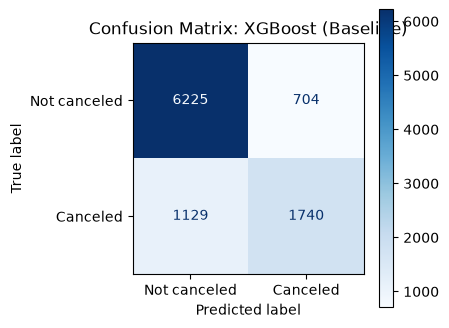

Best XGBoost Params: {'clf__colsample_bytree': 0.8, 'clf__learning_rate': 0.05, 'clf__max_depth': 8, 'clf__n_estimators': 400, 'clf__scale_pos_weight': 2.41, 'clf__subsample': 0.8}
Best CV F1: 0.6959

=== XGBoost (Tuned) ===
Train Accuracy: 0.8842 | Test Accuracy: 0.8022
              precision    recall  f1-score   support

Not canceled       0.90      0.81      0.85      6929
    Canceled       0.63      0.78      0.70      2869

    accuracy                           0.80      9798
   macro avg       0.76      0.79      0.77      9798
weighted avg       0.82      0.80      0.81      9798



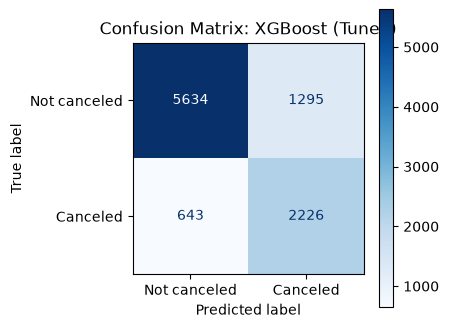

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('prep', ...), ('clf', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](26,)","['LeadTime','ArrivalDateYear','ArrivalDateMonth',...,'ADR', 'TotalOfSpecialRequests','HasCompany']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,26
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='pas

In [3]:
#Baseline AND Hyperparameter-Tuned XGBoost

# Untuned Baseline XGBoost
model_xgb_base = Pipeline([
    ("prep", clone(preprocess)),
    ("clf", XGBClassifier(
        tree_method="hist",
        eval_metric="logloss",
        random_state=RANDOM_STATE,
        n_jobs=-2,
        device="cuda",
    )),
])

evaluate_classifier("XGBoost (Baseline)", model_xgb_base, X_train, y_train, X_test, y_test, cv)

# Hyperparameter Tuned XGBoost
neg_pos_ratio = float((y_train == 0).sum() / (y_train == 1).sum())

xgb_tune_pipe = Pipeline([
    ("prep", clone(preprocess)),
    ("clf", XGBClassifier(
        tree_method="hist",
        eval_metric="logloss",
        random_state=RANDOM_STATE,
        n_jobs=1,   # Keep at 1 when GridSearchCV runs parallel workers
        device="cuda",
    )),
])

param_grid_xgb = {
    "clf__n_estimators": [200, 400],
    "clf__max_depth": [4, 6, 8],
    "clf__learning_rate": [0.05, 0.1],
    "clf__subsample": [0.8],
    "clf__colsample_bytree": [0.8],
    "clf__scale_pos_weight": [1.0, round(neg_pos_ratio, 2)],
}

grid_xgb = GridSearchCV(
    estimator=xgb_tune_pipe,
    param_grid=param_grid_xgb,
    scoring="f1",
    cv=cv,
    n_jobs=1,
    refit=True,
)

grid_xgb.fit(X_train, y_train)
print("Best XGBoost Params:", grid_xgb.best_params_)
print(f"Best CV F1: {grid_xgb.best_score_:.4f}\n")

model_xgb_tuned = grid_xgb.best_estimator_
evaluate_classifier("XGBoost (Tuned)", model_xgb_tuned, X_train, y_train, X_test, y_test, cv)

,Model,CV Accuracy,CV F1,CV ROC-AUC,Train Acc,Test Acc,Test Precision,Test Recall,Test F1,Test ROC-AUC,Test PR-AUC
0,XGBoost (Baseline),0.8157 ± 0.0031,0.6577 ± 0.0059,0.8744 ± 0.0005,0.8606,0.8129,0.7119,0.6065,0.6550,0.8689,0.7394
1,XGBoost (Tuned),0.8021 ± 0.0010,0.6959 ± 0.0018,0.8792 ± 0.0010,0.8842,0.8022,0.6322,0.7759,0.6967,0.8762,0.7520


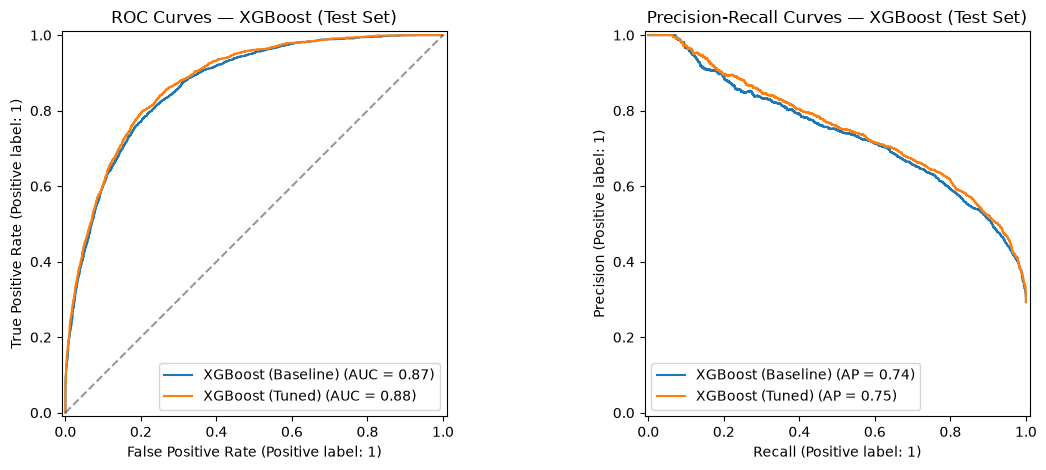

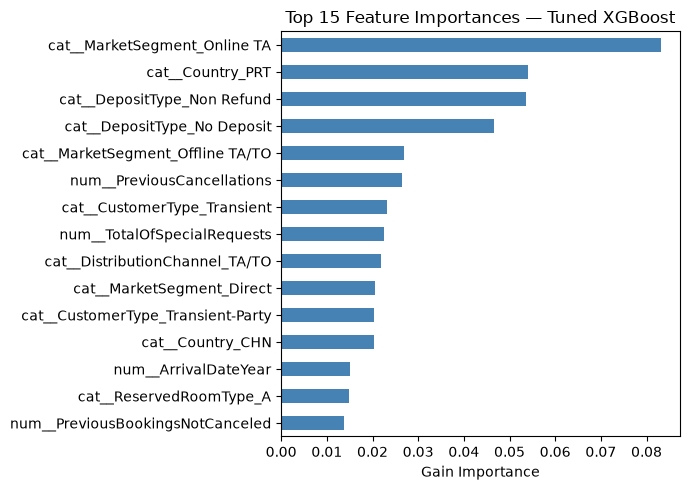

In [4]:
#Visualizing the results. (Summary Table, ROC/PR Curves & Top 15 Features)
summary_xgb = pd.DataFrame(results_log)
display(summary_xgb)

# ROC & Precision-Recall Curves
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
for name, est in fitted_models.items():
    RocCurveDisplay.from_estimator(est, X_test, y_test, ax=axes[0], name=name)
    PrecisionRecallDisplay.from_estimator(est, X_test, y_test, ax=axes[1], name=name)

axes[0].plot([0, 1], [0, 1], "k--", alpha=0.4)
axes[0].set_title("ROC Curves — XGBoost (Test Set)")
axes[1].set_title("Precision-Recall Curves — XGBoost (Test Set)")
plt.tight_layout()
plt.show()

# Top 15 Feature Importances
feature_names = model_xgb_tuned.named_steps["prep"].get_feature_names_out()
importances = model_xgb_tuned.named_steps["clf"].feature_importances_

feat_imp = (
    pd.Series(importances, index=feature_names)
    .sort_values(ascending=False)
    .head(15)
)

fig, ax = plt.subplots(figsize=(7, 5))
feat_imp.sort_values().plot(kind="barh", ax=ax, color="steelblue")
ax.set_title("Top 15 Feature Importances — Tuned XGBoost")
ax.set_xlabel("Gain Importance")
plt.tight_layout()
plt.show()